# Chuẩn bị UP-Fall
- Ảnh PNG từ ZIP Camera 1. Bản benchmark có 508 trial đóng góp ảnh.
- Tải từ [HAR-UP](https://sites.google.com/up.edu.mx/har-up/). CSV nhãn nguồn là CompleteDataSet.csv.
- Ghép timestamp theo từng trial, dùng cột Tag và lấy mỗi 6 ảnh theo thứ tự gốc.
- Ví dụ hiển thị các ảnh đứng, ngã và nằm trong cùng một trial.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "papercode").is_dir())
paper = root / "papercode"
prepare = paper / "prepare-dataset"
postures = ["Đi/đứng", "Nằm", "Đang ngã", "Ngồi"]

In [2]:
assignment = pd.read_csv(prepare / "splits/upfall.csv")
samples = prepare / "dataraw/upfall/examples"
print(f"Số ảnh của benchmark: {len(assignment):,}")
display(pd.crosstab(assignment["posture"], assignment["split"]))
display(assignment[["sample_id", "split", "cv_fold"]].head())

Số ảnh của benchmark: 44,245


split,train,validation
posture,,
P1,16064,4016
P2,10968,2742
P3,1142,285
P4,7222,1806


,sample_id,split,cv_fold
0,upfall_s01_a01_t01_c1_f000000,train,2
1,upfall_s01_a01_t01_c1_f000006,train,0
2,upfall_s01_a01_t01_c1_f000012,train,2
3,upfall_s01_a01_t01_c1_f000018,train,0
4,upfall_s01_a01_t01_c1_f000024,train,0


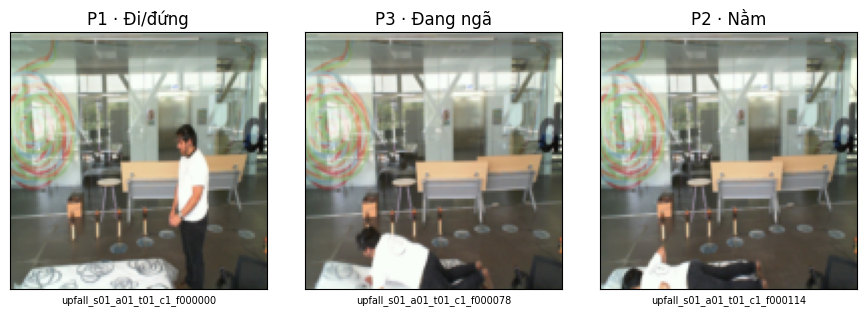

In [3]:
import matplotlib.pyplot as plt

photos = sorted((samples / "images").glob("upfall_s01_a01_t01_c1_f000*.png"))[:3]
fig, axes = plt.subplots(1, len(photos), figsize=(9, 3))
for ax, photo in zip(np.atleast_1d(axes), photos):
    row = assignment.loc[assignment.sample_id.eq(photo.stem)].iloc[0]
    ax.imshow(Image.open(photo))
    ax.set_title(f"{row.posture} · {postures[row.label]}")
    ax.set_xlabel(photo.stem, fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## Dựng lại từ file nguồn
- Đặt ZIP với tên S01_A01_T1_Camera1.zip và CompleteDataSet.csv trong dataraw/upfall.
- Bật PREPARE_RAW để ghép nhãn và lưu ảnh RGB 128×128 dưới prepared/upfall.

In [4]:
import re
from zipfile import ZipFile

PREPARE_RAW = False
tag_to_label = {1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 0, 7: 0, 8: 3, 11: 1}

def upfall_labels(raw):
    labels = pd.read_csv(raw / "CompleteDataSet.csv", skiprows=[1],
        usecols=["Subject", "Activity", "Trial", "TimeStamps", "Tag"])
    return labels.drop_duplicates(["Subject", "Activity", "Trial", "TimeStamps"]).set_index(
        ["Subject", "Activity", "Trial", "TimeStamps"])["Tag"].to_dict()

def save_upfall_images(raw, output, expected):
    tags = upfall_labels(raw)
    rows = []
    (output / "images").mkdir(parents=True, exist_ok=True)
    seen = set()
    pattern = re.compile(r"S(\d+)_A(\d+)_T(\d+)_Camera1\.zip", re.IGNORECASE)
    stamp_pattern = re.compile(r"\d{4}-\d{2}-\d{2}T\d{2}_\d{2}_\d{2}\.\d+")
    for archive in sorted(raw.glob("*.zip")):
        match = pattern.fullmatch(archive.name)
        if match is None:
            continue
        subject, activity, trial = map(int, match.groups())
        with ZipFile(archive) as images:
            timeline = []
            for name in images.namelist():
                stamp = stamp_pattern.search(Path(name).stem)
                if Path(name).suffix.lower() == ".png" and stamp:
                    timeline.append((stamp.group().replace("_", ":"), name))
            for index, (stamp, name) in enumerate(sorted(timeline)):
                if index % 6:
                    continue
                label = tag_to_label.get(tags.get((subject, activity, trial, stamp)))
                if label is None:
                    continue
                sample = f"upfall_s{subject:02d}_a{activity:02d}_t{trial:02d}_c1_f{index:06d}"
                if sample not in expected:
                    continue
                if label != expected[sample]:
                    raise ValueError(f"Tag khác split đã công bố: {sample}")
                relative = f"images/{sample}.png"
                with images.open(name) as stream, Image.open(stream) as frame:
                    rgb = ImageOps.exif_transpose(frame).convert("RGB")
                    rgb.resize((128, 128), Image.Resampling.BILINEAR).save(output / relative)
                rows.append((sample, label, stamp, relative))
                seen.add(sample)
    if seen != set(expected):
        raise ValueError(f"Còn thiếu {len(set(expected) - seen)} ảnh thuộc split đã công bố")
    return pd.DataFrame(rows, columns=["sample_id", "label", "timestamp", "image_path"])

if PREPARE_RAW:
    output = prepare / "prepared/upfall"
    manifest = save_upfall_images(samples.parent, output, assignment.set_index("sample_id")["label"].to_dict())
    manifest.to_csv(output / "manifest.csv", index=False)

Cột cv_fold từ 0 đến 4 áp dụng cho tập train. Validation được giữ riêng với cv_fold = -1.